# Spaza shop sales analysis

**Shop:** Mama Zulu's Spaza, Greytown (fictional)  
**Data:** one year of sales (2025), generated by `scripts/generate_sample_data.py`

This notebook walks through the questions a shop owner asks — *what makes me money, when are customers here, and what should I stock?* — using the `spaza_analyser` package.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make the package importable from notebooks/

import pandas as pd
from IPython.display import Image, Markdown, display

from spaza_analyser import analysis, charts
from spaza_analyser.data import load_sales

pd.options.display.float_format = "{:,.2f}".format
df = load_sales("../data/sales_2025.csv")
df.head()

,receipt_id,timestamp,product,category,quantity,unit_price,unit_cost,payment_method,revenue,cost,profit,date,month,weekday,hour
0,R100000,2025-01-01 06:08:00,Tinned pilchards 400g,Groceries,1,29.99,24.50,Cash,29.99,24.50,5.49,2025-01-01,2025-01,Wednesday,6
1,R100001,2025-01-01 06:18:00,Brown bread loaf,Bread & bakery,1,17.99,14.80,Cash,17.99,14.80,3.19,2025-01-01,2025-01,Wednesday,6
2,R100002,2025-01-01 06:24:00,Cold drink 500ml,Drinks,1,13.99,10.20,Cash,13.99,10.20,3.79,2025-01-01,2025-01,Wednesday,6
3,R100003,2025-01-01 06:28:00,White bread loaf,Bread & bakery,1,19.99,16.50,Cash,19.99,16.50,3.49,2025-01-01,2025-01,Wednesday,6
4,R100004,2025-01-01 06:39:00,Sweets (loose),Snacks & sweets,1,1.00,0.45,Cash,1.00,0.45,0.55,2025-01-01,2025-01,Wednesday,6


## 1. The big picture

In [2]:
s = analysis.summarise(df)
display(
    Markdown(f"""
| Measure | Value |
|---|---|
| Sales | {analysis.rand(s.revenue)} |
| Gross profit | {analysis.rand(s.profit)} |
| Margin | {s.margin_pct:.1f}% |
| Average sales per day | {analysis.rand(s.avg_daily_revenue)} |
""")
)


| Measure | Value |
|---|---|
| Sales | R 1 492 200.89 |
| Gross profit | R 286 606.19 |
| Margin | 19.2% |
| Average sales per day | R 4 088.22 |


## 2. Monthly trend

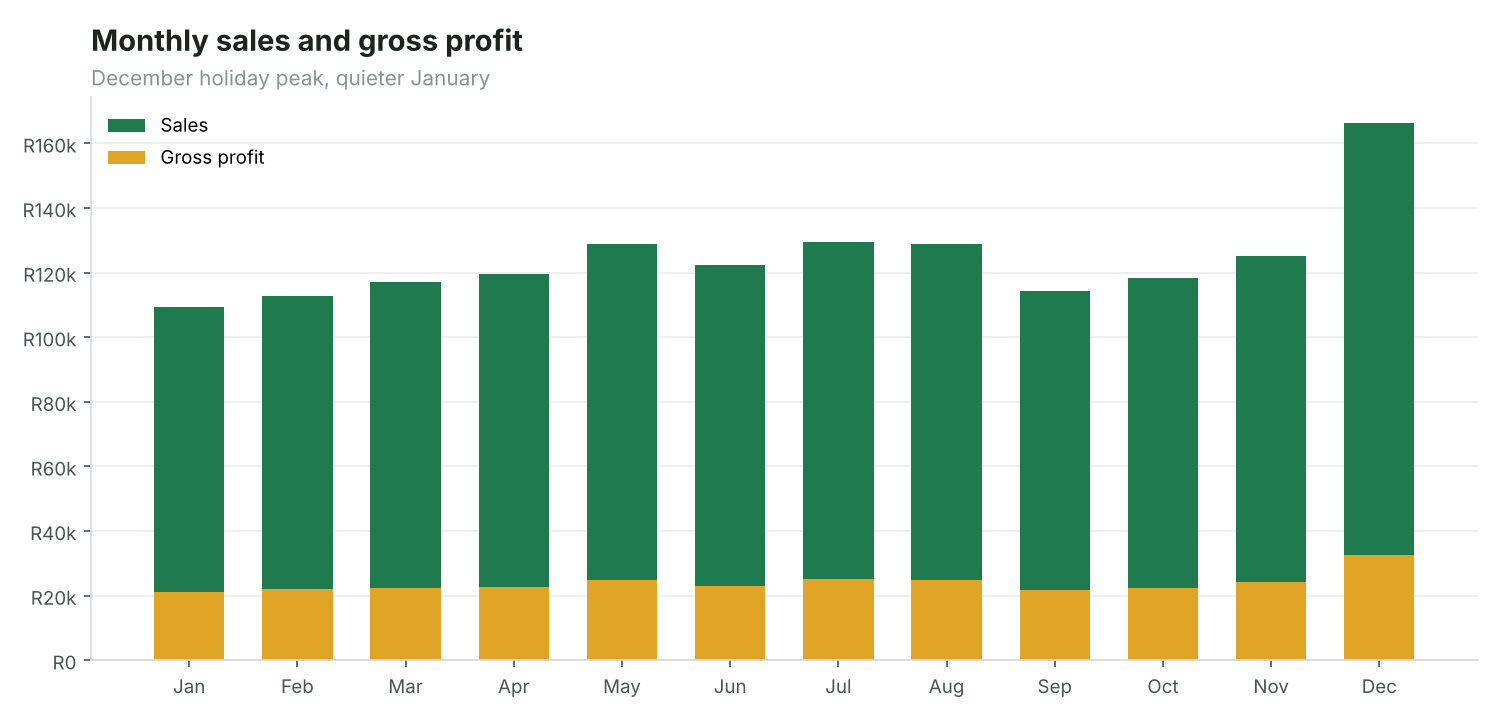

,revenue,cost,profit,margin_pct,revenue_change_pct
month,,,,,
2025-01,"109,380.65","88,248.85","21,131.80",19.32,NaN
2025-02,"112,901.14","90,976.40","21,924.74",19.42,3.22
2025-03,"117,168.54","94,736.05","22,432.49",19.15,3.78
2025-04,"119,453.47","96,728.20","22,725.27",19.02,1.95
2025-05,"128,962.75","104,227.05","24,735.70",19.18,7.96
2025-06,"122,315.21","99,216.15","23,099.06",18.88,-5.15
2025-07,"129,486.75","104,471.75","25,015.00",19.32,5.86
2025-08,"128,733.44","103,903.15","24,830.29",19.29,-0.58
2025-09,"114,188.38","92,537.10","21,651.28",18.96,-11.30


In [3]:
CHARTS = Path("../reports/charts")
display(Image(charts.monthly_revenue_chart(df, CHARTS)))
analysis.monthly_totals(df)

December is the clear peak (holiday spending and bonuses) and January is the slowest month, when budgets are tight after the festive season.

## 3. What makes the money?

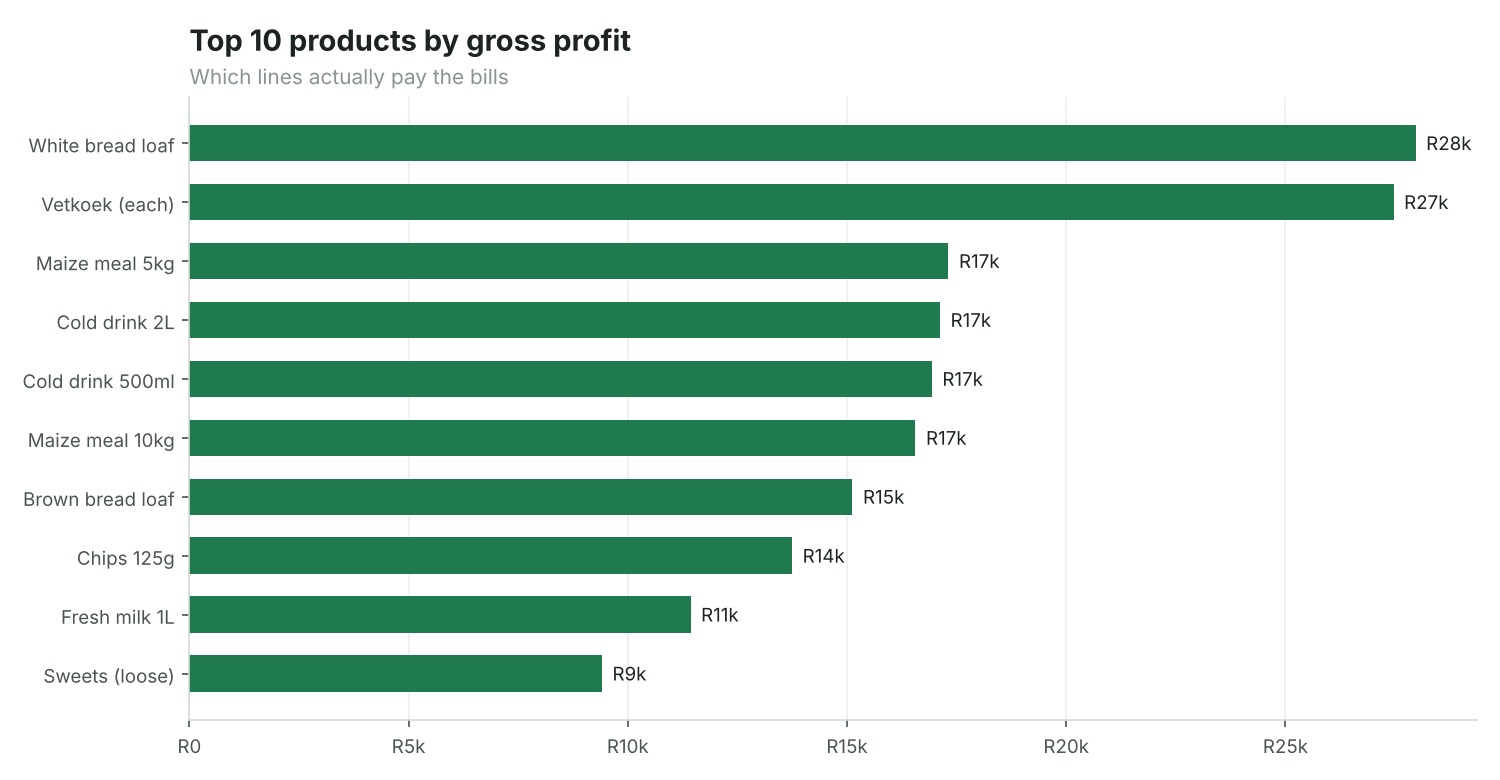

,product,category,units,revenue,profit,margin_pct,profit_share_pct
0,White bread loaf,Bread & bakery,8014,"160,199.86","27,968.86",17.46,9.76
1,Vetkoek (each),Bread & bakery,9471,"47,355.00","27,465.90",58.00,9.58
2,Maize meal 5kg,Groceries,1444,"108,285.56","17,313.56",15.99,6.04
3,Cold drink 2L,Drinks,2638,"73,837.62","17,120.62",23.19,5.97
4,Cold drink 500ml,Drinks,4468,"62,507.32","16,933.72",27.09,5.91
5,Maize meal 10kg,Groceries,789,"110,452.11","16,561.11",14.99,5.78
6,Brown bread loaf,Bread & bakery,4741,"85,290.59","15,123.79",17.73,5.28
7,Chips 125g,Snacks & sweets,2995,"50,885.05","13,747.05",27.02,4.80
8,Fresh milk 1L,Dairy & eggs,3016,"69,337.84","11,430.64",16.49,3.99
9,Sweets (loose),Snacks & sweets,17108,"17,108.00","9,409.40",55.00,3.28


In [4]:
display(Image(charts.top_products_chart(df, CHARTS)))
analysis.top_products(df, 10)

Bread and vetkoek are small items but sell every day, so they earn the most profit. Airtime sells a lot but at a 6% margin, so it's there to bring customers in rather than to earn.

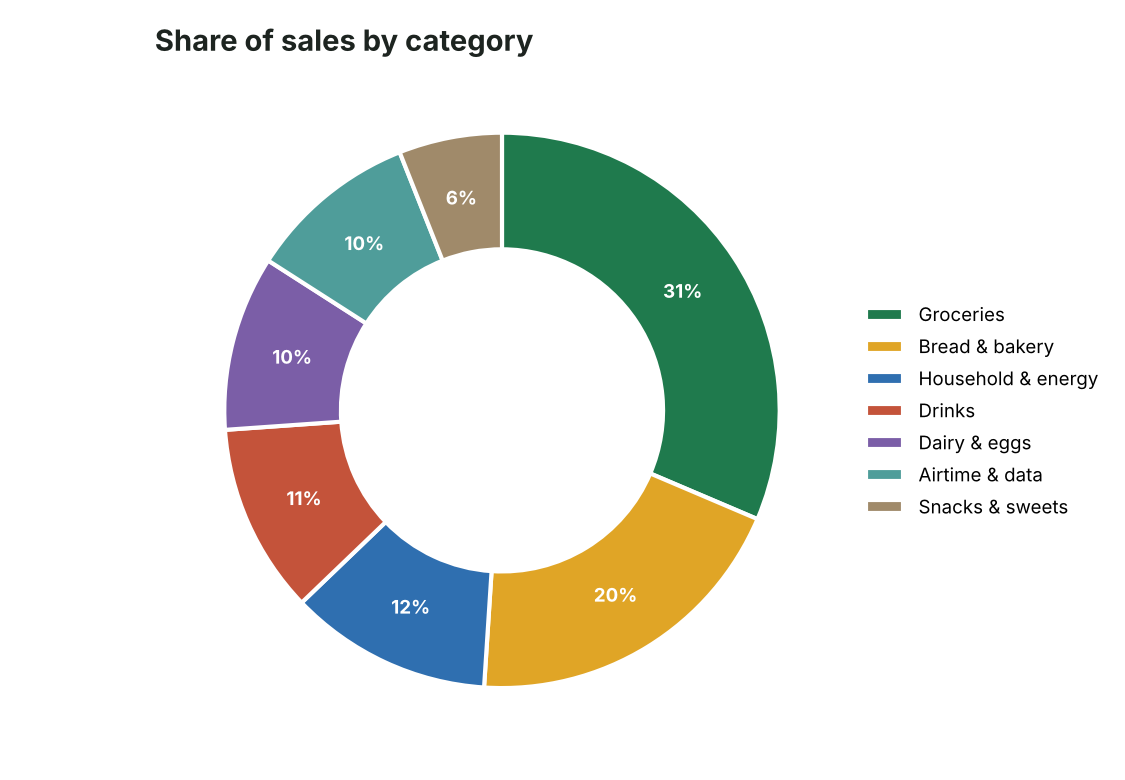

,revenue,profit,revenue_share_pct,margin_pct
category,,,,
Groceries,"468,613.49","76,691.09",31.40,16.37
Bread & bakery,"292,845.45","70,558.55",19.63,24.09
Household & energy,"176,034.05","36,138.45",11.80,20.53
Drinks,"164,983.48","40,002.08",11.06,24.25
Dairy & eggs,"152,014.90","25,673.50",10.19,16.89
Airtime & data,"148,082.00","8,852.30",9.92,5.98
Snacks & sweets,"89,627.52","28,690.22",6.01,32.01


In [5]:
display(Image(charts.category_chart(df, CHARTS)))
analysis.category_breakdown(df)

## 4. When do customers shop?

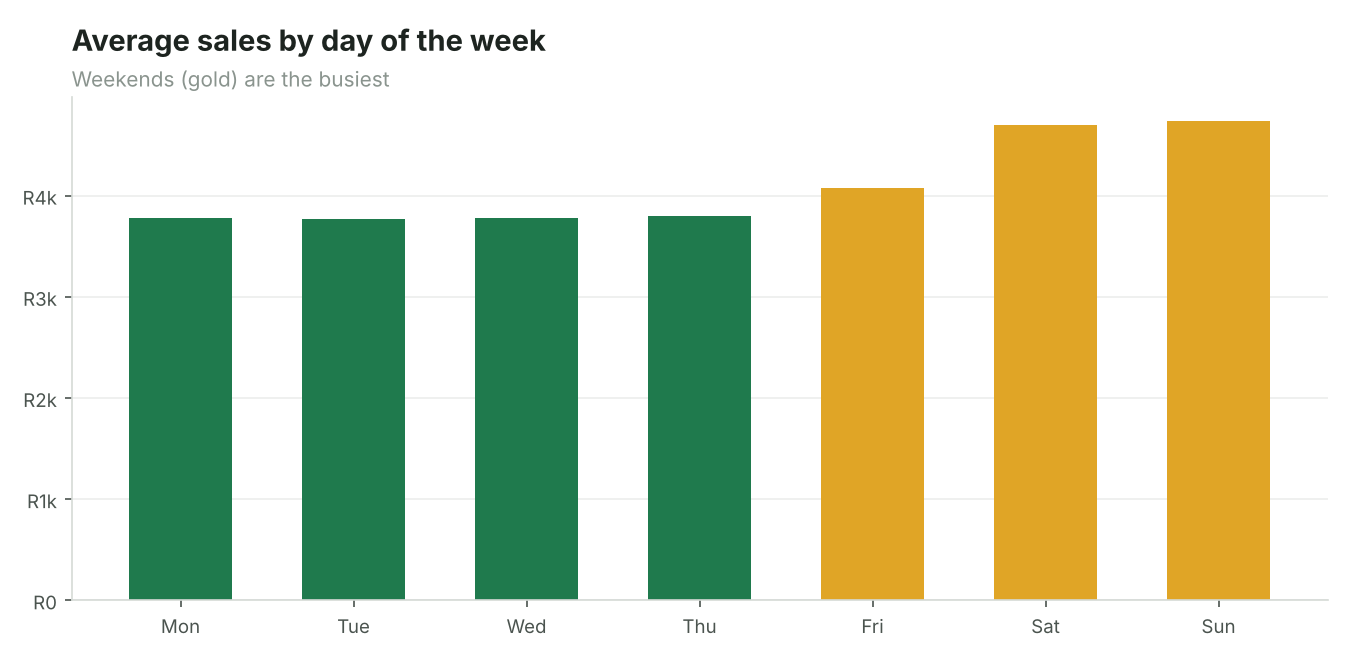

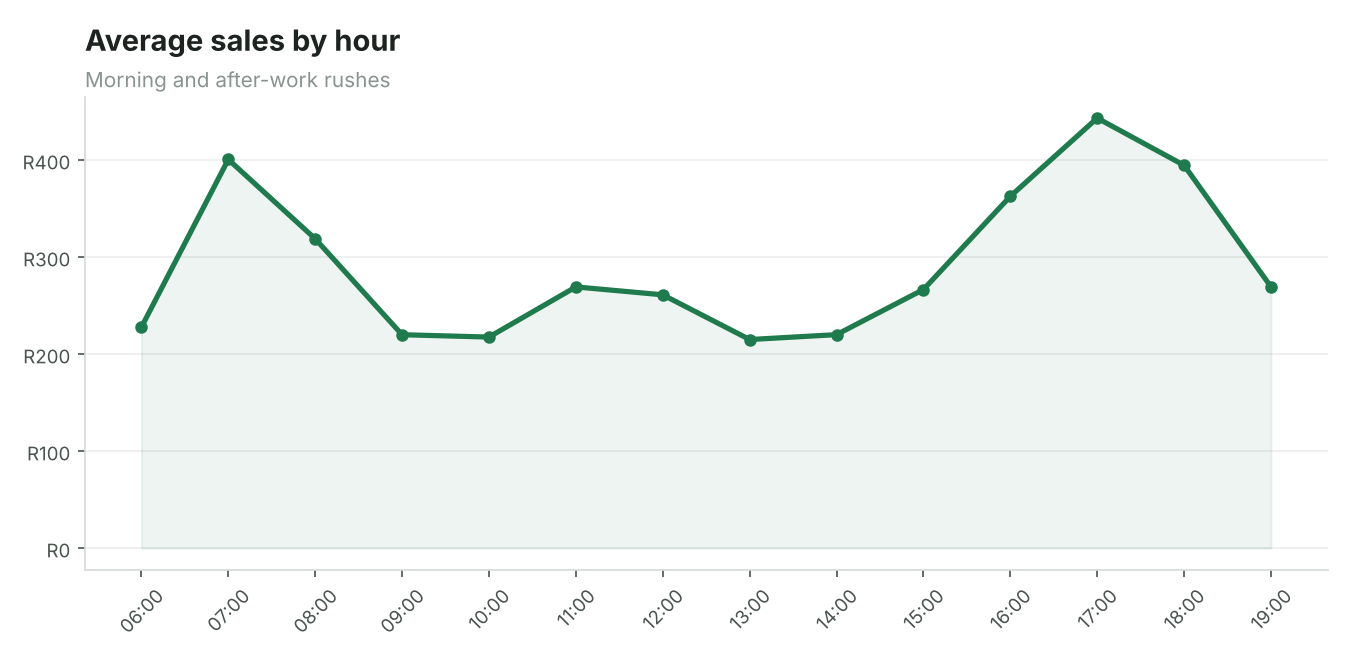

In [6]:
display(Image(charts.weekday_chart(df, CHARTS)))
display(Image(charts.hourly_chart(df, CHARTS)))

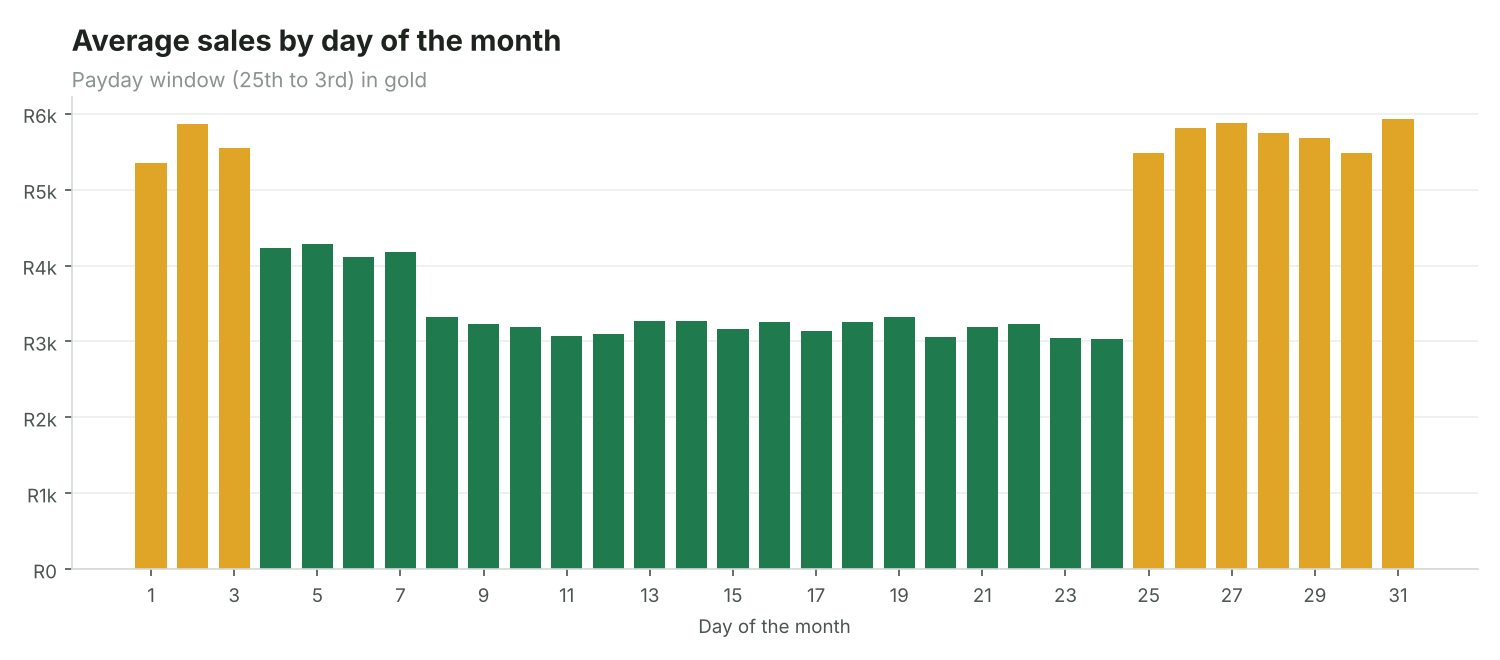

,avg_daily_revenue,days
period,,
Payday (25th-3rd),"5,667.76",113
Rest of month,"3,379.94",252


In [7]:
display(Image(charts.payday_chart(df, CHARTS)))
analysis.payday_effect(df)

Sales jump in the **payday window (25th to 3rd)**, driven by bulk staples like maize meal, rice and cooking oil. Restocking before the 25th avoids running out when demand is highest.

## 5. Seasonal stock

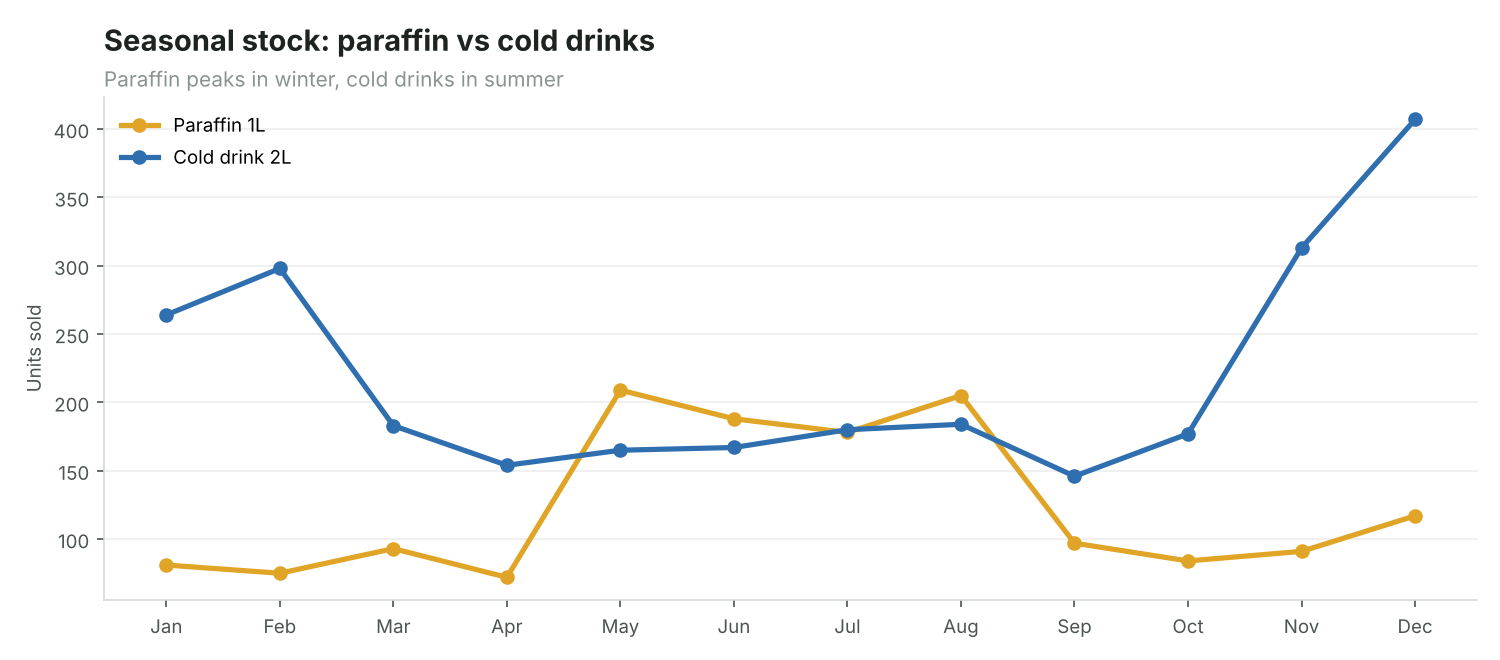

In [8]:
display(Image(charts.seasonal_chart(df, CHARTS)))

Paraffin and candles more than double in winter (May to August); cold drinks peak in summer. Ordering to the season frees up cash and shelf space.

## 6. How customers pay

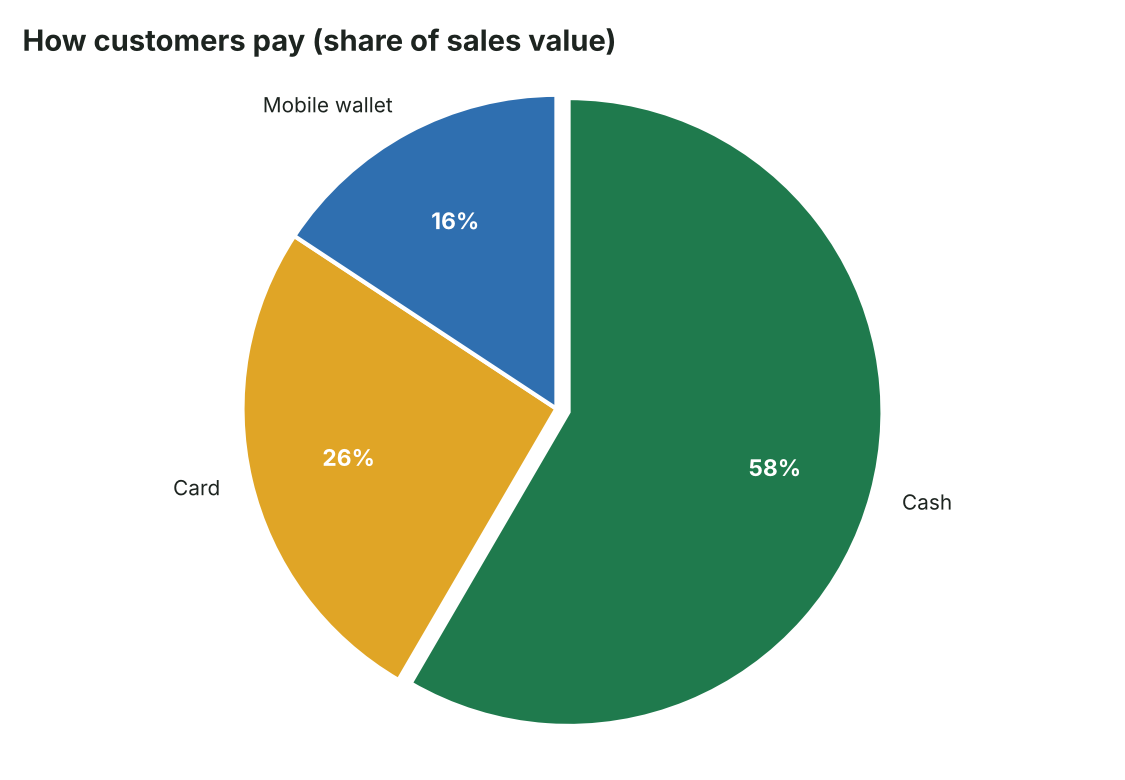

,sales,revenue,share_of_value_pct
payment_method,,,
Cash,35291,"871,315.56",58.39
Card,13687,"386,233.86",25.88
Mobile wallet,8851,"234,651.47",15.73


In [9]:
display(Image(charts.payment_chart(df, CHARTS)))
analysis.payment_mix(df)

Cash still makes up more than half of sales value, so the shop needs a safe cash routine and regular banking. Card and mobile-wallet payments are more common for bigger baskets, so accepting them helps on payday when people buy in bulk.

## 7. The same questions in SQL

The sales are also loaded into a **SQLite database** with two tables — `products` (each item once) and `sales` (every sale line) — so the analysis can be done in SQL too. The saved queries live in `sql/queries/`.

In [10]:
from spaza_analyser.database import build_database, run_query

conn = build_database(df)  # in-memory SQLite database
pd.read_sql_query("""
    SELECT p.category,
           ROUND(SUM(s.quantity * p.unit_price), 2) AS revenue,
           ROUND(100.0 * SUM(s.quantity * p.unit_price)
                 / SUM(SUM(s.quantity * p.unit_price)) OVER (), 1) AS share_pct
    FROM sales AS s
    JOIN products AS p USING (product_id)
    GROUP BY p.category
    ORDER BY revenue DESC
""", conn)

,category,revenue,share_pct
0,Groceries,"468,613.49",31.40
1,Bread & bakery,"292,845.45",19.60
2,Household & energy,"176,034.05",11.80
3,Drinks,"164,983.48",11.10
4,Dairy & eggs,"152,014.90",10.20
5,Airtime & data,"148,082.00",9.90
6,Snacks & sweets,"89,627.52",6.00


A saved query with a CTE and `CASE` confirms the payday effect found with pandas:

In [11]:
run_query(conn, "05_payday_effect")

,period,days,avg_daily_revenue
0,Payday (25th-3rd),113,"5,667.76"
1,Rest of month,252,"3,379.94"


And `ROW_NUMBER()` finds the best seller in each category:

In [12]:
run_query(conn, "07_best_seller_per_category")

,category,product,units
0,Snacks & sweets,Sweets (loose),17108
1,Bread & bakery,Vetkoek (each),9471
2,Drinks,Cold drink 500ml,4468
3,Airtime & data,Airtime R10,3822
4,Dairy & eggs,Fresh milk 1L,3016
5,Household & energy,Paraffin 1L,1490
6,Groceries,Maize meal 5kg,1444


## 8. Recommendations

In [13]:
for line in analysis.insights(df):
    print("•", line)

• The shop made R 1 492 200.89 in sales and R 286 606.19 gross profit (19.2% margin) over 365 trading days.
• Best month was December (R 166 171.25); quietest was January (R 109 380.65).
• White bread loaf is the biggest earner, bringing in R 27 968.86 profit (9.8% of the total).
• Payday days (25th to 3rd) average 68% more sales than the rest of the month: stock up on bulk staples before the 25th.
• Sunday is the busiest day and Tuesday the quietest.
• The busiest hour is 17:00, so restock shelves before then.
• Airtime & data has the thinnest margin (6.0%): it brings customers in but earns little on its own.


**Actions for the owner**

1. Order bulk staples before the 25th of each month to catch payday demand.
2. Never run out of bread and vetkoek — they are the top profit earners.
3. Have the shelves full before 07:00 and 17:00, the two daily rushes.
4. Switch stock with the seasons: paraffin and candles in winter, cold drinks in summer.
5. Treat airtime as a footfall driver, not a profit line.